# 01 · Sequence EDA and alignment

**Advanced movement representation learning — chapter 1.** Status: `AUTHORED — AWAITING USER EXECUTION` (2026-10-11). No cell has been run by the author.

## Research objective
Look at the forty-yard-dash sequences as recorded, before any neural model: what each channel shows, how two attempts of one athlete differ, what the recording leaves out, and which common axis makes sequences comparable without erasing what distinguishes athletes.

## Question and working hypothesis
*Which alignment and which channels give curves that are repeatable between an athlete's attempts?* Working hypothesis, taken from the executed sprint rescue: because 58.5 % of forty recordings start with the athlete already moving, an axis anchored on the athlete's **state** (speed reached) is more repeatable than an axis anchored on the **recording clock**. It may be wrong; the comparison below measures it.

## Inputs (written by notebook 00, same `RUN_MODE`)
`sequence_manifest` (Combine attempt), `athlete_registry` (athlete), `split_registry` (athlete × repeat), and the frame source `gold/phase_03/combine_frame_kinematics` (frame, 10 Hz).

## What this notebook saves
`sequence_frames` (sequence × frame, the cached model input), `sequence_summary`, `alignment_comparison`, `preprocessing_decisions`, and figures `AM01_*`.

## What it does not do
No NFL value is read. No model is fitted. Examples are chosen by rule and are **descriptive**.

## Configuration

In [1]:
RUN_MODE = 'full'        # must match the mode notebook 00 was run with
FORCE_REBUILD = False
SAVE_FIGURES = True
SAVE_TABLES = True
SAVE_MODELS = True
DEVICE = 'auto'
SEED = 20261011
NUM_WORKERS = 0
BATCH_SIZE = 32
MAX_EPOCHS = 3

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.features.config import KinematicsConfig
from nflbdb.research.advanced_movement import alignment as al
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import eda
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement import visualizations as viz
from nflbdb.research.advanced_movement.artifacts import AdvStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES,
                                save_tables=SAVE_TABLES, save_models=SAVE_MODELS, device=DEVICE, seed=SEED,
                                num_workers=NUM_WORKERS, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
store = AdvStore(cfg, controls)
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(110)

# Prerequisites: artifacts of notebook 00 in the SAME run mode (smoke artifacts are never used for a full run).
PREVIOUS = '00_research_setup_and_data_audit.ipynb'
manifest = store.require(amd.MANIFEST, PREVIOUS)
athletes = store.require(amd.ATHLETES, PREVIOUS)
splits = store.require(amd.SPLITS, PREVIOUS)
previous = store.read_json('research_metadata', PREVIOUS)
if previous.get('seed') != controls.seed:
    raise ValueError(f'SEED = {controls.seed} but notebook 00 was run with seed {previous.get("seed")}: use the same seed')
display(Markdown(f'**Run mode: `{controls.run_mode}`** · {athletes.height} athletes · '
                 f'{manifest.filter(pl.col("eligible_primary")).height} eligible sequences'))
display(store.describe())

**Run mode: `full`** · 510 athletes · 793 eligible sequences

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_movement"""
"""datasets (Parquet + schema sidecar)""","""warehouse/gold/advanced_movement"""
"""figures (PNG 300 DPI, SVG, PDF)""","""reports/figures/advanced_movement"""
"""models and fitted preprocessing""","""artifacts/models/advanced_movement"""


## 1 · From frames to sequences

**Grain.** One sequence = the valid frames of the longest segment of one eligible forty attempt — the same frames the Phase 03 sprint model uses. Nothing is re-smoothed, and every derived quantity is computed inside one sequence.

**Channels.** Let $(x_i, y_i)$ be the smoothed position on frame $i$ of a sequence with $n$ frames, $\theta = \operatorname{atan2}(y_{n-1}-y_0,\; x_{n-1}-x_0)$ the direction of the run line, and $h_i$ the direction of motion.

$$\text{along}_i = (x_i-x_0)\cos\theta + (y_i-y_0)\sin\theta \qquad \text{lat\_dev}_i = (y_i-y_0)\cos\theta - (x_i-x_0)\sin\theta$$
$$\text{dist}_i = \sum_{j=1}^{i} \lVert p_j - p_{j-1} \rVert \qquad \text{head\_sin}_i = \sin(h_i-\theta),\;\; \text{head\_cos}_i = \cos(h_i-\theta)$$

All of them are unchanged when the field coordinates are translated or rotated. Absolute `x`, `y` and the absolute heading angle are **not** channels: they encode the lane and the recording convention. The direction of motion is a circular quantity and enters only as sine and cosine.

`a_lat`, `lat_dev`, `yaw_rate` and `head_sin` flip sign under a mirror image of the run. Whether the Combine coordinate frame has a fixed handedness is unverified, so their sign is not interpretable across cohorts.

In [3]:
inputs = amd.AdvInputs(cfg, acfg, athletes['nfl_id'].to_list() if controls.smoke else None)
half_window = KinematicsConfig().smoothing.window // 2     # Savitzky–Golay half-window of the persisted kinematics


def build_sequences():
    frames = seq.build_sequence_frames(inputs.frames(), manifest, acfg, half_window)
    return {seq.SEQ_FRAMES.name: frames,
            eda.SUMMARY.name: eda.sequence_summary(seq.SequenceSet.from_frames(frames, manifest))}


built = store.build('SEQUENCES', [seq.SEQ_FRAMES, eda.SUMMARY], build_sequences,
                    params={'config': acfg.params(), 'half_window': half_window},
                    files=[store.parquet(amd.MANIFEST), *inputs.p03.dataset_files('combine_frame_kinematics')])
seq_frames, summary = built[seq.SEQ_FRAMES.name], built[eda.SUMMARY.name]
ss = seq.SequenceSet.from_frames(seq_frames, manifest)

names = dict(athletes.select('nfl_id', 'display_name').iter_rows())
positions = dict(athletes.select('nfl_id', 'position_group').iter_rows())
seq_position = ss.meta['position_group'].fill_null('?').to_numpy()
seq_cohort = ss.meta['draft_year'].cast(pl.String).fill_null('?').to_numpy()
display(Markdown(f'**{ss.n} sequences of {np.unique(ss.nfl_ids).size} athletes** · {int(ss.mask.sum()):,} real frames · '
                 f'padded array {ss.X.shape} ({ss.X.nbytes / 2 ** 20:.2f} MB) · half-window {half_window} frames'))
display(summary.select(pl.exclude('seq_id', 'nfl_id')).describe())

13:40:57 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:SEQUENCES] computing (never run)
13:40:58 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:SEQUENCES] sequence_frames: 41,500 rows → warehouse/gold/advanced_movement/sequence_frames.parquet
13:40:58 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:SEQUENCES] sequence_summary: 793 rows → warehouse/gold/advanced_movement/sequence_summary.parquet


**793 sequences of 418 athletes** · 41,500 real frames · padded array (793, 90, 11) (2.99 MB) · half-window 3 frames

statistic,position_group,draft_year,attempt_order,n_frames,duration_s,path_yd,first_speed,peak_speed,frames_after_peak,peak_a_tan,max_abs_lat_dev,pos_resid_rms,a_tan_roughness,share_boundary
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""793""",793.0,793.0,793.0,793.0,793.0,793.0,793.0,793.0,793.0,793.0,793.0,793.0,793.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",null,2024.0,1.472888,52.332913,5.133291,40.473464,0.605624,10.394503,4.283733,5.659533,0.36683,0.009226,0.378716,0.115145
"""std""",null,0.813398,0.499579,3.592942,0.359294,0.547459,0.310817,0.777634,3.516045,0.774705,0.279366,0.00405,0.22583,0.007308
"""min""","""DB""",2023.0,1.0,45.0,4.4,38.700851,0.02662,8.352391,0.0,3.356823,0.045402,0.001293,0.100108,0.066667
"""25%""",null,2023.0,1.0,50.0,4.9,40.117157,0.416497,9.727072,0.0,5.130458,0.204825,0.004794,0.265083,0.109091
"""50%""",null,2024.0,1.0,51.0,5.0,40.469288,0.561925,10.603507,4.0,5.649959,0.307755,0.010849,0.321522,0.117647
"""75%""",null,2025.0,2.0,55.0,5.4,40.795803,0.723159,11.002577,6.0,6.113066,0.450405,0.011843,0.428204,0.12
"""max""","""WR""",2025.0,2.0,90.0,8.9,43.848621,3.360816,11.873118,36.0,10.583838,3.444064,0.030834,2.898681,0.133333


## 2 · Channels, variable length and missingness

Sequences have different lengths, so the array is zero-padded and carries two masks: real frames, and real **and** defined values per channel. Padding is never an observation: every statistic, alignment and (later) loss uses the masks, and the sequence object refuses arrays whose padded cells are not exactly zero.

channel,unit,kind,proposed_input,meaning
str,str,str,bool,str
"""t_rel""","""s""","""clock""",false,"""seconds since the first valid frame of the recording"""
"""dist""","""yd""","""geometry""",false,"""smoothed path length since the first valid frame"""
"""along""","""yd""","""geometry""",false,"""progress along the straight line from first to last frame"""
"""speed""","""yd/s""","""kinematic""",true,"""magnitude of the smoothed velocity"""
"""a_tan""","""yd/s²""","""kinematic""",true,"""rate of change of speed (signed)"""
"""a_lat""","""yd/s²""","""kinematic""",true,"""lateral acceleration (signed; mirror-dependent)"""
"""yaw_rate""","""deg/s""","""kinematic""",false,"""rate of change of the direction of motion"""
"""lat_dev""","""yd""","""geometry""",true,"""sideways deviation from the first-to-last line"""
"""head_sin""","""–""","""geometry""",false,"""sine of the direction of motion relative to the run line"""


raw_column,why_it_is_not_a_channel
str,str
"""x_s""","""absolute field position: encodes lane and recording convention, not the athlete"""
"""y_s""","""absolute field position: encodes lane and recording convention, not the athlete"""
"""heading""","""absolute angle: circular and dependent on the run direction; replaced by head_sin / head_cos"""
"""s""","""vendor speed: superseded by the derived speed (Phase 03 M1)"""
"""a""","""vendor acceleration: a magnitude, not a signed tangential value (Phase 03 M1)"""


channel,n_frames,share_undefined
str,i64,f64
"""t_rel""",41500,0.0
"""dist""",41500,0.0
"""along""",41500,0.0
"""speed""",41500,0.0
"""a_tan""",41500,0.000289
"""a_lat""",41500,0.000289
"""yaw_rate""",41500,0.03453
"""lat_dev""",41500,0.0
"""head_sin""",41500,0.03453


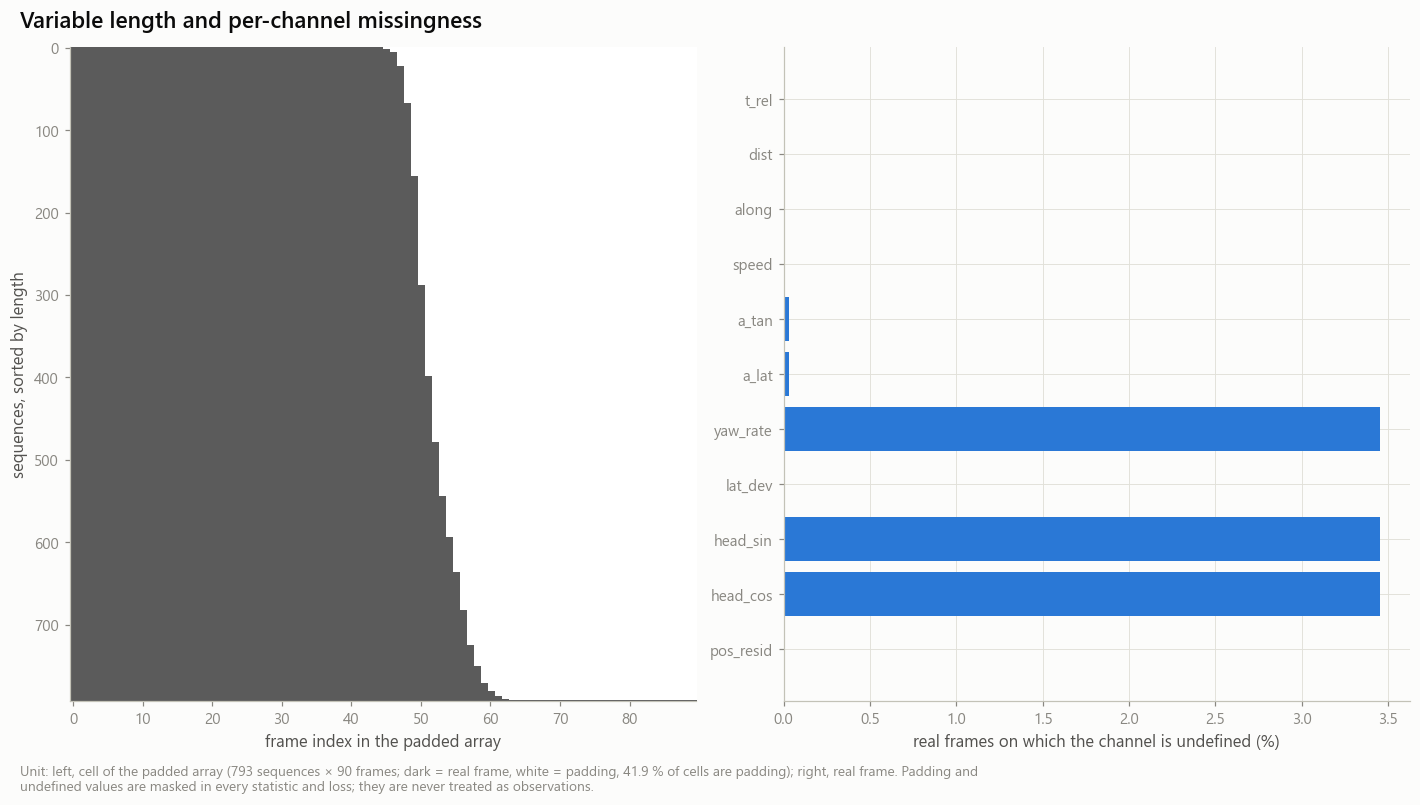

In [4]:
display(pl.DataFrame([{'channel': c.name, 'unit': c.unit, 'kind': c.kind, 'proposed_input': c.default, 'meaning': c.meaning}
                      for c in amc.CHANNELS]))
display(pl.DataFrame([{'raw_column': k, 'why_it_is_not_a_channel': v} for k, v in amc.EXCLUDED_RAW.items()]))
display(ss.channel_missingness())
store.show(viz.plot_variable_length(ss), 'AM01_01_variable_length_and_missingness',
           {'channel_missingness': ss.channel_missingness(), 'lengths': summary.select('seq_id', 'n_frames')},
           source='sequence_frames', n=f'{ss.n} sequences')

## 3 · Representative attempts

Three sequences chosen by rule: the ones closest to the 10th, 50th and 90th percentile of peak speed. Four signals each, against time since the first recorded frame. Shaded frames lie inside the smoothing half-window of a segment edge.

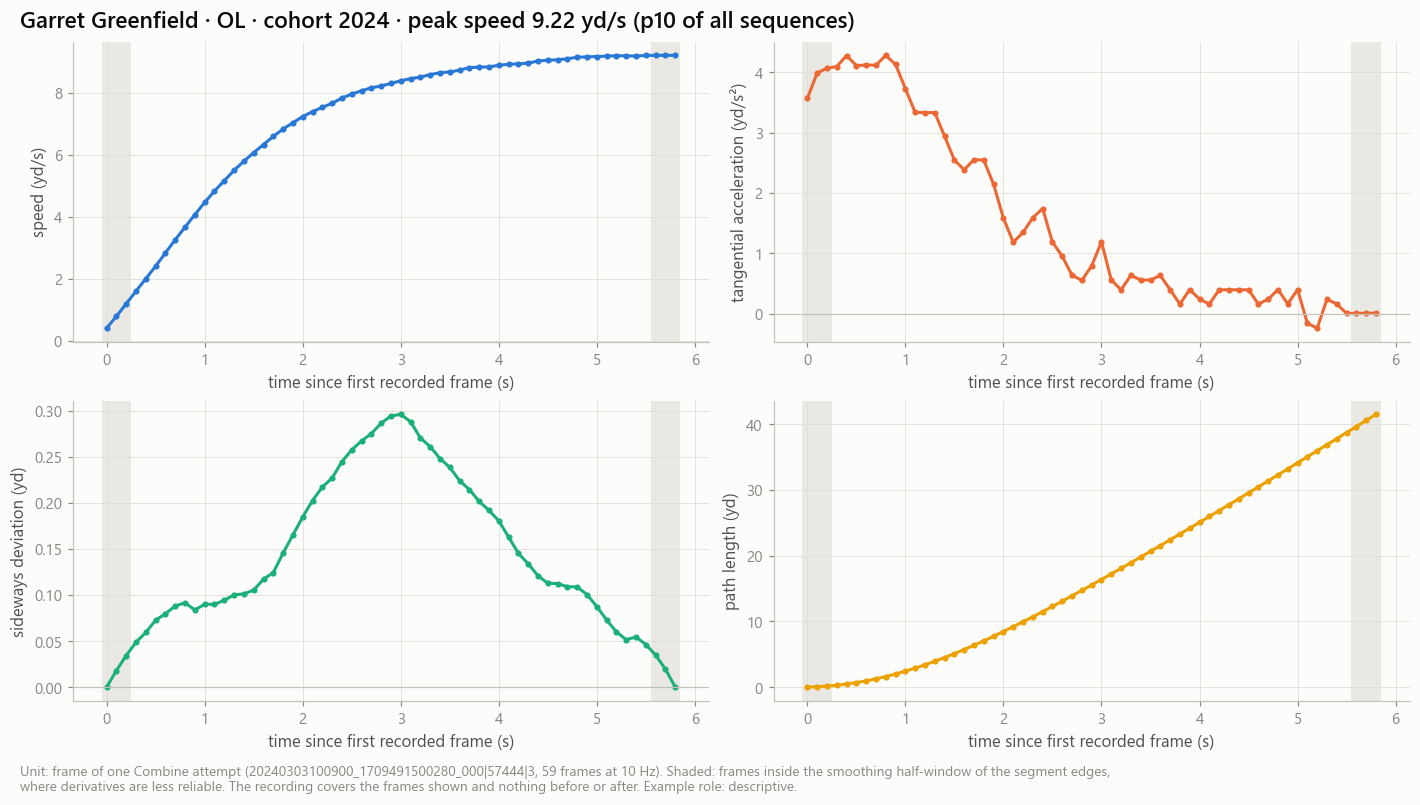

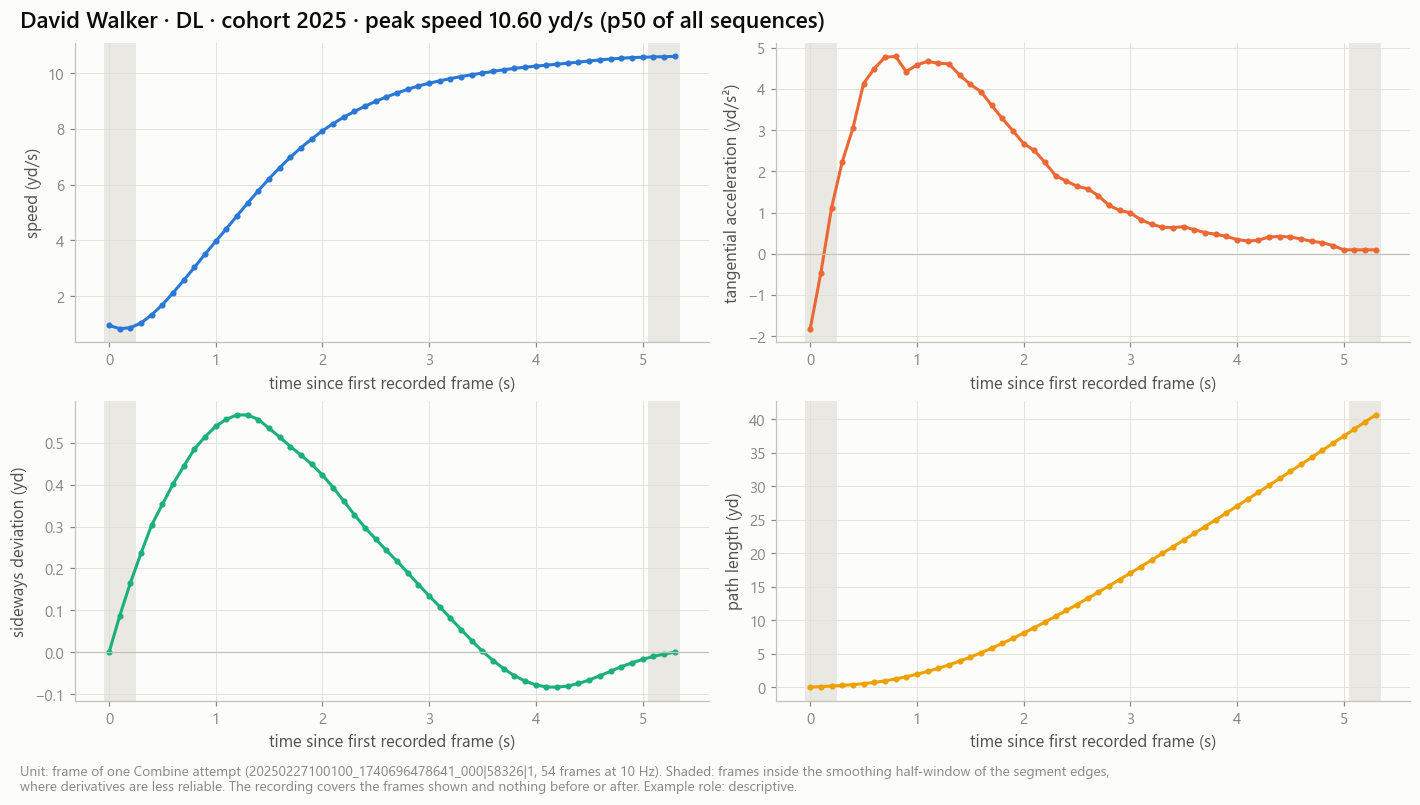

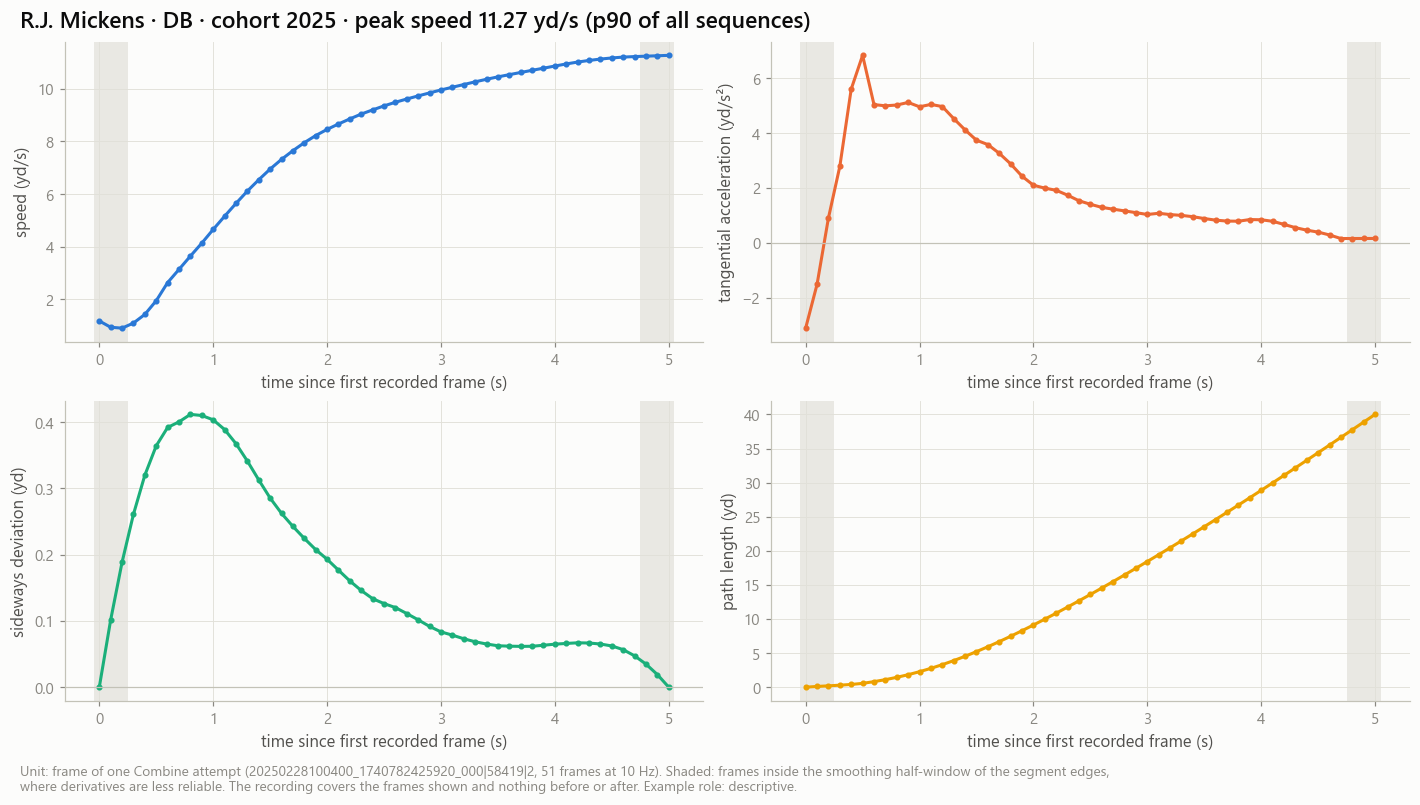

In [5]:
for label, seq_id in zip(('p10', 'p50', 'p90'), eda.representative_sequences(summary, by='peak_speed')):
    row = summary.filter(pl.col('seq_id') == seq_id).row(0, named=True)
    title = (f'{names.get(row["nfl_id"], row["nfl_id"])} · {row["position_group"]} · cohort {row["draft_year"]} · '
             f'peak speed {row["peak_speed"]:.2f} yd/s ({label} of all sequences)')
    store.show(viz.plot_attempt_panels(ss, seq_id, role='descriptive', title=title), f'AM01_02_attempt_{label}_peak_speed',
               {'frames': seq_frames.filter(pl.col('seq_id') == seq_id)}, source='sequence_frames', n=f'{row["n_frames"]} frames')

## 4 · The same athlete, attempt after attempt

Athletes with at least two sequences, drawn with a fixed seed and spread over position groups. Top row: speed against the recording clock. Bottom row: acceleration against speed — the phase plane, which does not depend on where the recording starts.

nfl_id,position_group,draft_year,attempt_order,n_frames,first_speed,peak_speed,frames_after_peak
i64,str,i64,i64,i64,f64,f64,i64
55982,"""OL""",2023,1,56,0.727068,9.847569,0
55982,"""OL""",2023,2,54,0.598207,9.893115,5
57145,"""DB""",2024,1,49,0.591057,10.738201,6
57145,"""DB""",2024,2,49,0.910539,10.70244,6
57356,"""DL""",2024,1,50,0.723159,10.666726,5
57356,"""DL""",2024,2,52,0.750378,10.547861,8
58380,"""TE""",2025,1,53,0.630404,10.111432,7
58380,"""TE""",2025,2,53,0.380929,10.136662,7


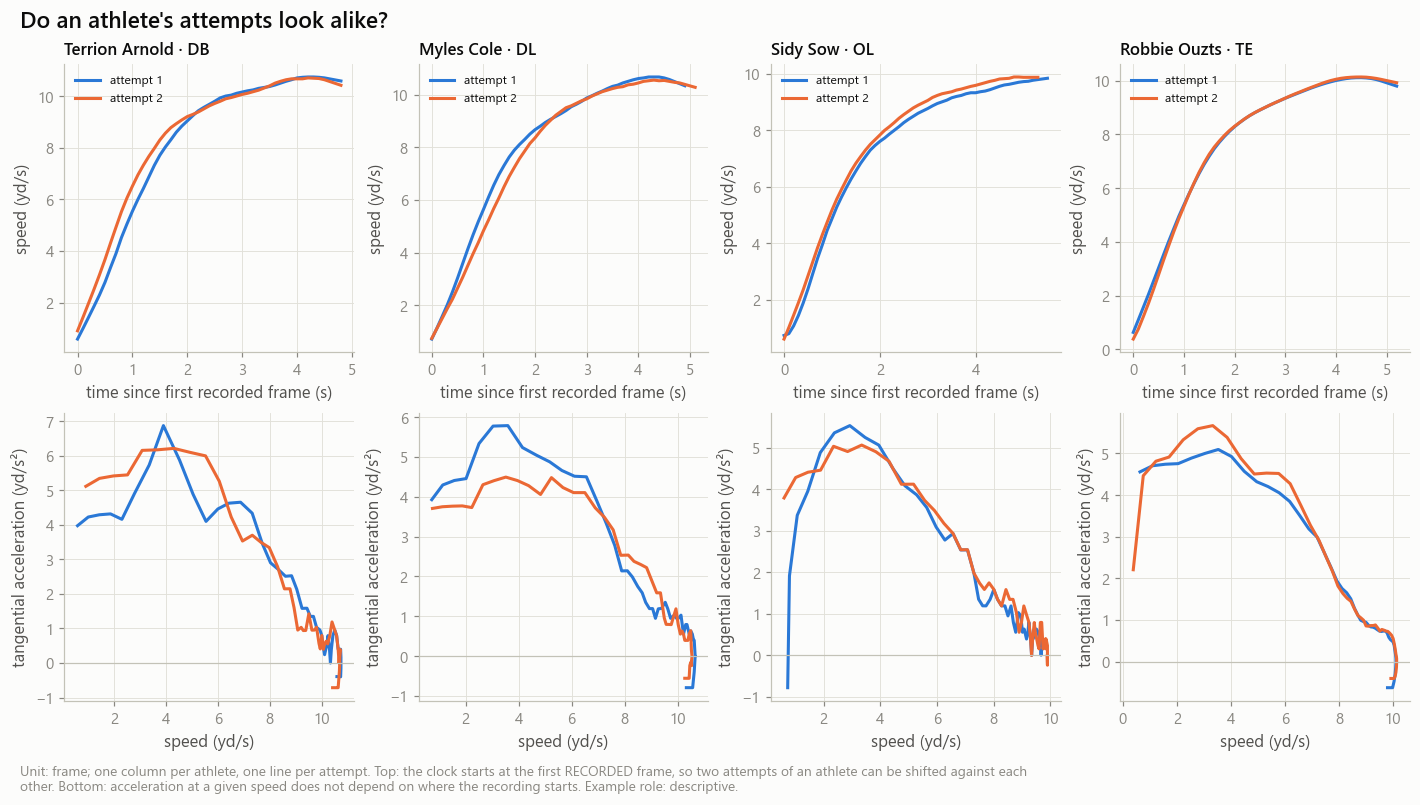

In [6]:
repeat_examples = eda.repeat_athletes(summary, k=4, seed=controls.seed)
display(summary.filter(pl.col('nfl_id').is_in(repeat_examples)).sort('nfl_id', 'attempt_order').select(
    'nfl_id', 'position_group', 'draft_year', 'attempt_order', 'n_frames', 'first_speed', 'peak_speed', 'frames_after_peak'))
store.show(viz.plot_repeat_attempts(ss, repeat_examples, names, role='descriptive'), 'AM01_03_same_athlete_repeated_attempts',
           {'frames': seq_frames.filter(pl.col('nfl_id').is_in(repeat_examples)).select('seq_id', 'nfl_id', 'frame', 't_rel', 'speed', 'a_tan')},
           publication=True, source='sequence_frames', n=f'{len(repeat_examples)} athletes')

## 5 · Same stopwatch, different run?

Pairs of athletes of the same position whose **official forty differs by at most 0.01 s**, first attempts with a comparable recording start, ordered by the largest difference in peak acceleration. This is the picture the project's question is about. It is one attempt per athlete: whether such a difference is repeatable is measured in notebook 05, and whether it matters in the NFL in notebooks 06–07.

position_group,seq_id_a,name_a,forty_a,seq_id_b,name_b,forty_b,d_peak_a_tan
str,str,str,f64,str,str,f64,f64
"""WR""","""20240302100700_1709411187871_000|57155|1""","""Ladd McConkey""",4.39,"""20240302100700_1709410796245_000|57256|1""","""Jacob Cowing""",4.38,4.051052
"""OL""","""64068a12e3d8e72dcddcb01f-2023|55982|1""","""Sidy Sow""",5.07,"""20240303101000_1709497074489_000|57240|1""","""Mason McCormick""",5.08,3.965917
"""OL""","""20240303100900_1709489409250_000|57126|1""","""Joe Alt""",5.05,"""20250302100900_1740939621140_000|58373|1""","""Drew Kendall""",5.05,3.519536


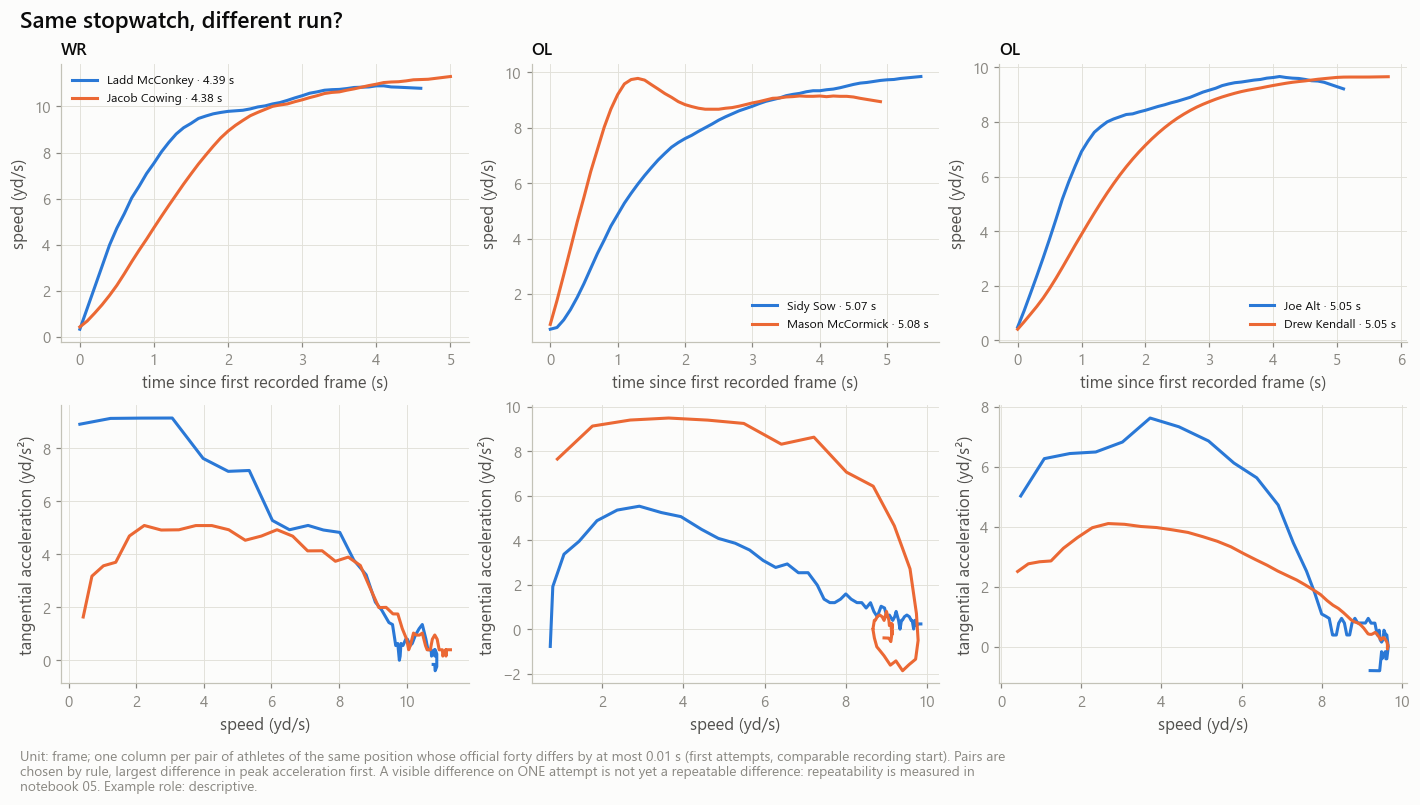

In [7]:
forty_pairs = eda.similar_forty_pairs(summary, athletes, k=3, tol_s=0.01)
display(forty_pairs)
store.show(viz.plot_matched_forty(ss, forty_pairs, role='descriptive'), 'AM01_04_same_official_forty_different_run',
           {'pairs': forty_pairs}, publication=True, source='sequence_frames + athlete_registry', n=f'{forty_pairs.height} pairs')

## 6 · Positions and draft cohorts

The four alignments are computed here once and reused below. Curves are summarised per group by the median and the inter-quartile range **across sequences** (attempts, not athletes).

Position groups differ in speed by a large margin, so a representation can look informative while only encoding position. Cohorts differ in tracking noise (2025 has about a quarter of the positional noise of 2023/24), so a representation can also encode the cohort. Both are tested as nuisance in notebook 05.

method,axis,grid_points,channels
str,str,i64,str
"""elapsed_time""","""time since the first recorded frame (s)""",61,"""speed, a_tan, lat_dev, dist"""
"""normalized_time""","""fraction of the recorded duration (–)""",64,"""speed, a_tan, lat_dev, t_rel, dist"""
"""distance""","""path length since the first recorded frame (yd)""",81,"""speed, a_tan, lat_dev, t_rel"""
"""speed_phase""","""speed level reached (rising phase) (yd/s)""",43,"""a_tan, lat_dev, t_rel, dist"""


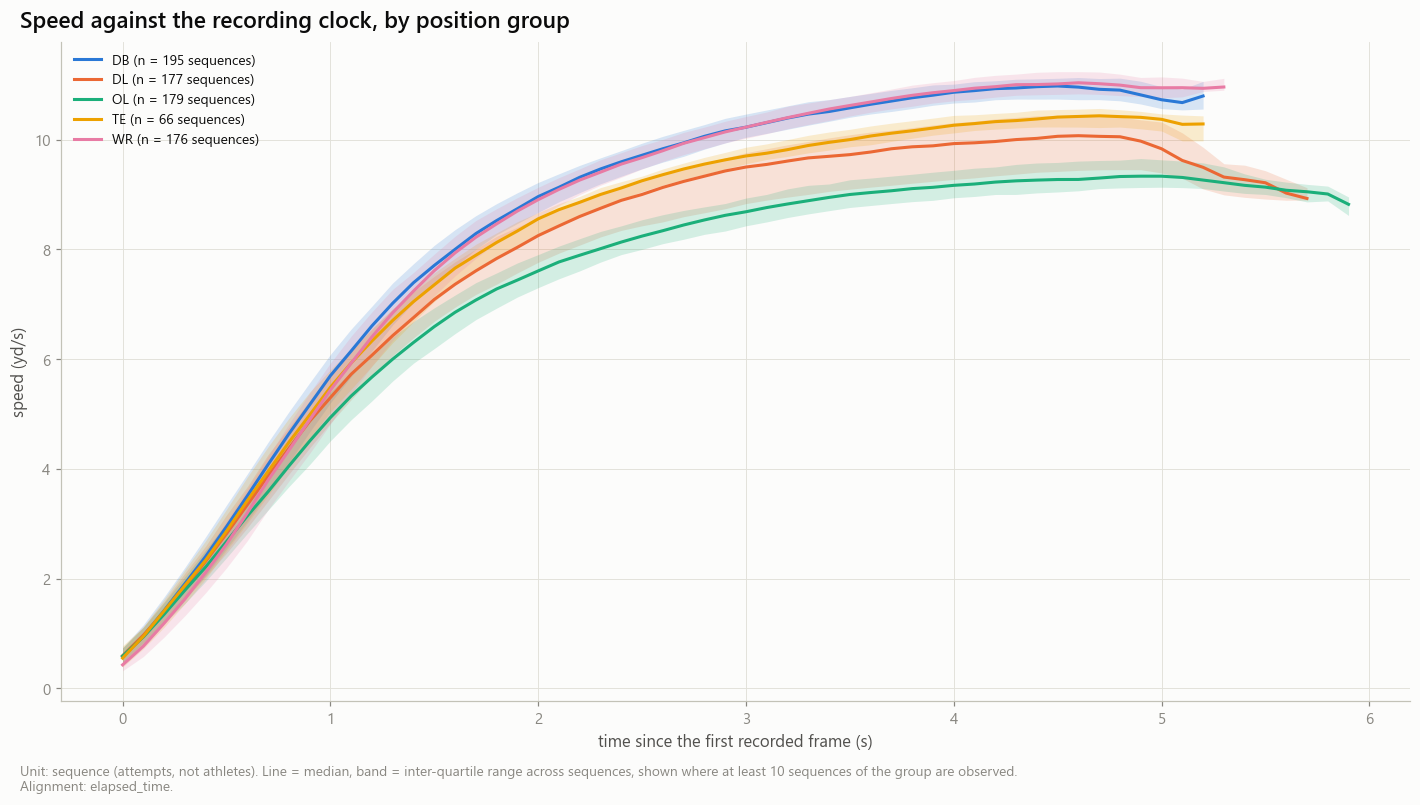

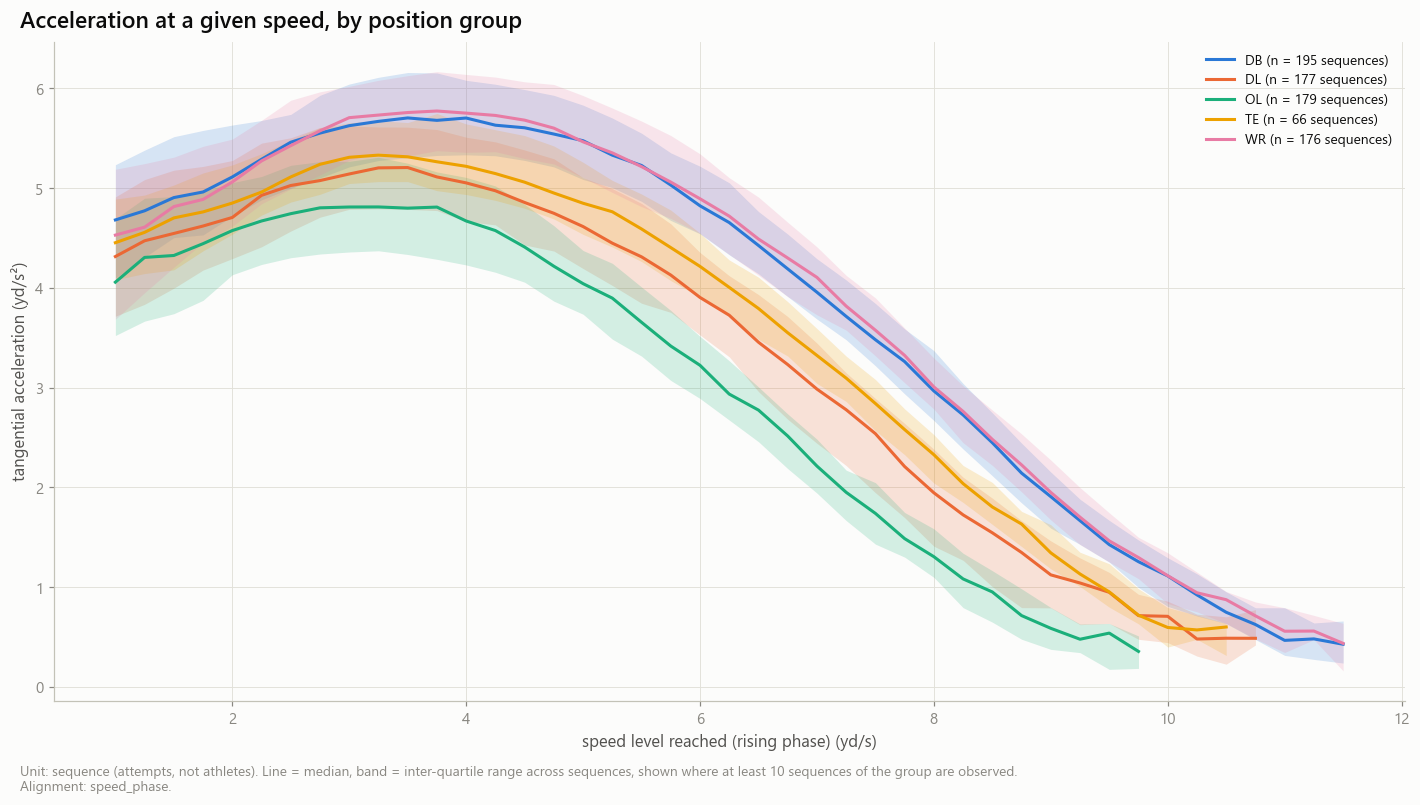

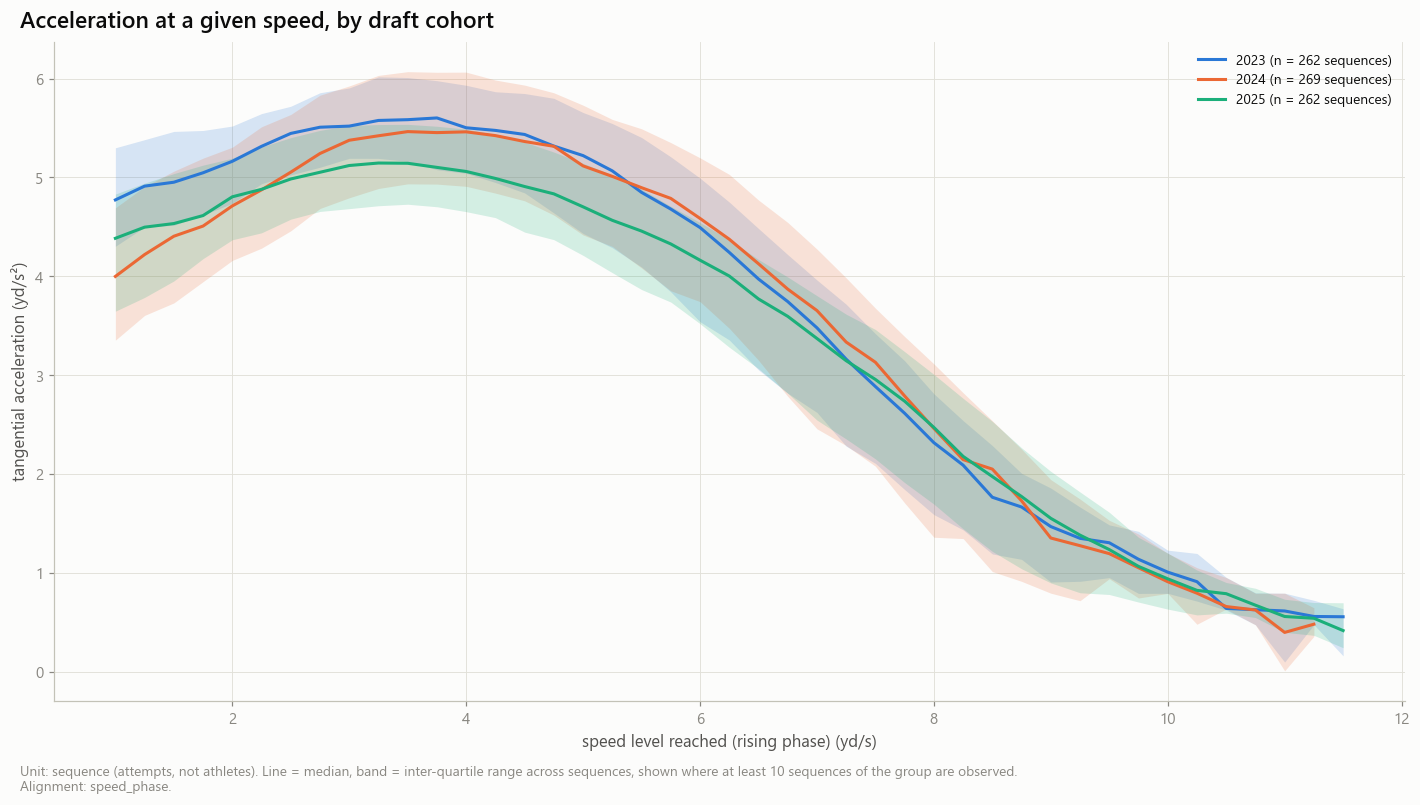

In [8]:
EDA_CHANNELS = ['speed', 'a_tan', 'lat_dev', 't_rel', 'dist']
aligned = al.align_all(ss, acfg, EDA_CHANNELS)     # each method drops the channel that is its own axis
display(pl.DataFrame([{'method': m, 'axis': f'{c.grid_name} ({c.grid_unit})', 'grid_points': c.grid.size,
                       'channels': ', '.join(c.channels)} for m, c in aligned.items()]))

store.show(viz.plot_group_curves(aligned['elapsed_time'], 'speed', seq_position, 'Speed against the recording clock, by position group'),
           'AM01_05_speed_by_position_elapsed_time', source='sequence_frames', n=f'{ss.n} sequences')
store.show(viz.plot_group_curves(aligned['speed_phase'], 'a_tan', seq_position, 'Acceleration at a given speed, by position group'),
           'AM01_06_acceleration_by_position_speed_phase', source='sequence_frames', n=f'{ss.n} sequences')
store.show(viz.plot_group_curves(aligned['speed_phase'], 'a_tan', seq_cohort, 'Acceleration at a given speed, by draft cohort'),
           'AM01_07_acceleration_by_cohort_speed_phase', source='sequence_frames', n=f'{ss.n} sequences')

## 7 · What the recording holds: start, duration, censoring, noise

- **Left-censoring.** A first-frame speed above zero means the recording began after the athlete started.
- **Right-censoring.** Zero frames after the speed peak means the recording ends while the athlete is at or near top speed; no plateau is recorded.
- **Noise.** Positional residual and acceleration roughness per sequence, by cohort.

The quality scenarios `S0_all ⊃ S1_structural ⊃ S2_signal ⊃ S3_no_boundary` come from Phase 04 Study Q. None is applied by default; the counts below show what each would cost in athletes.

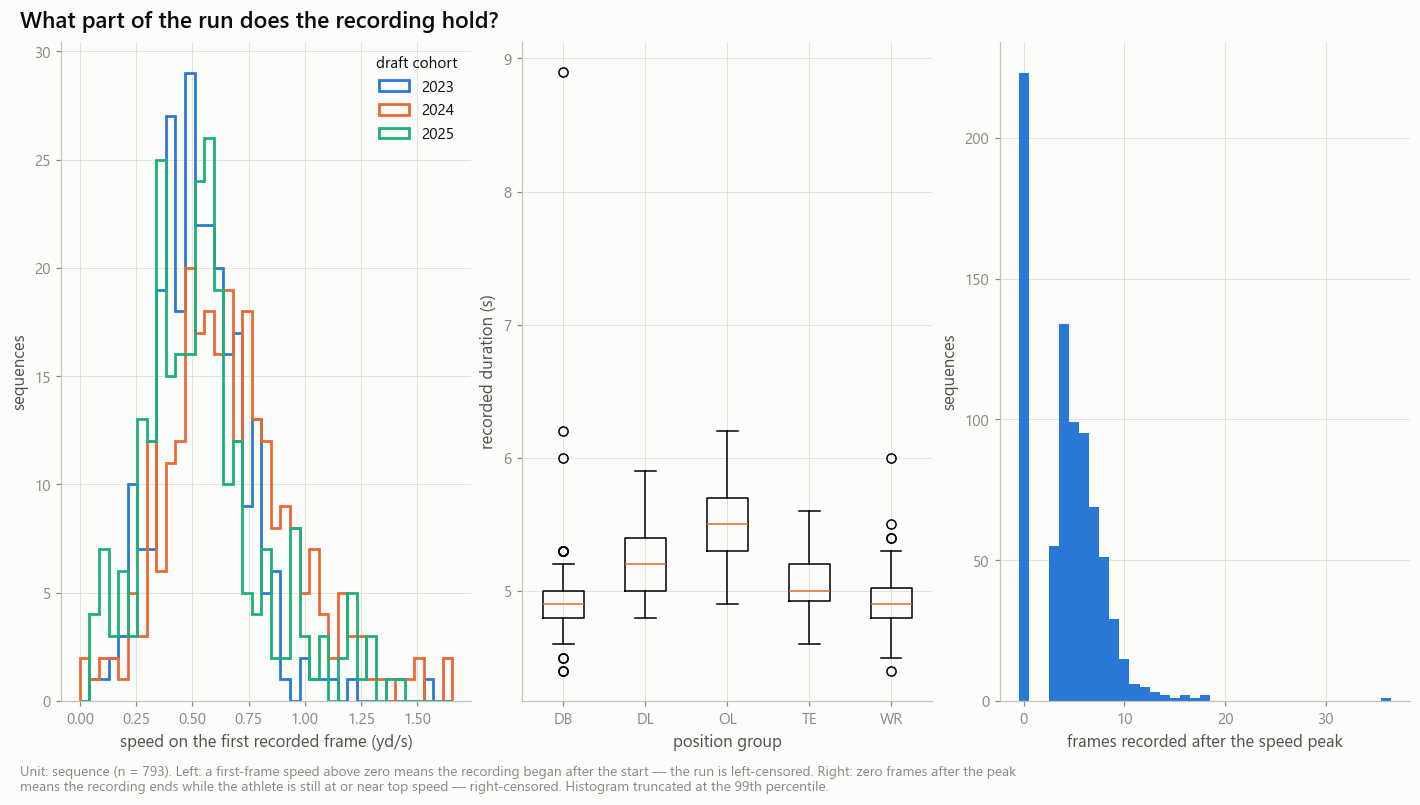

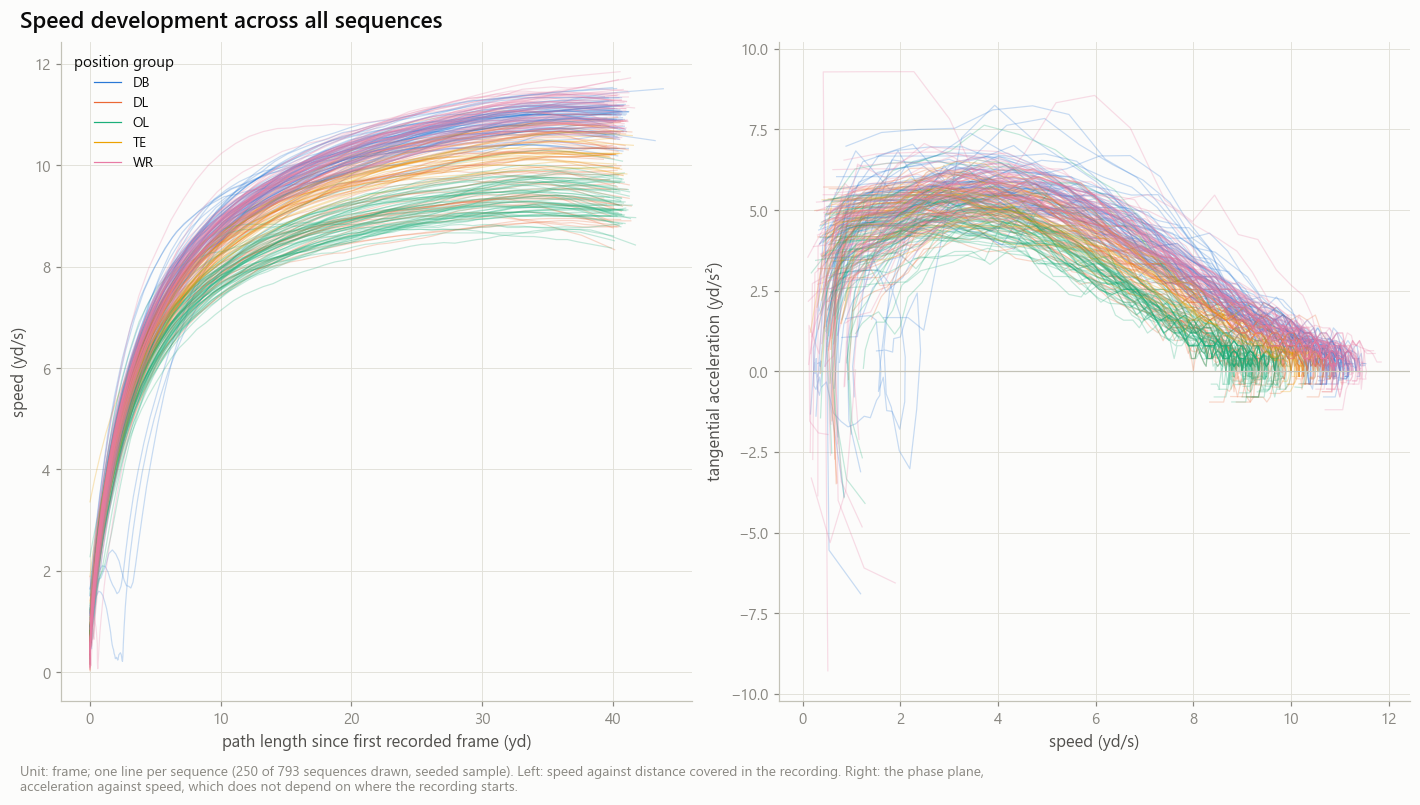

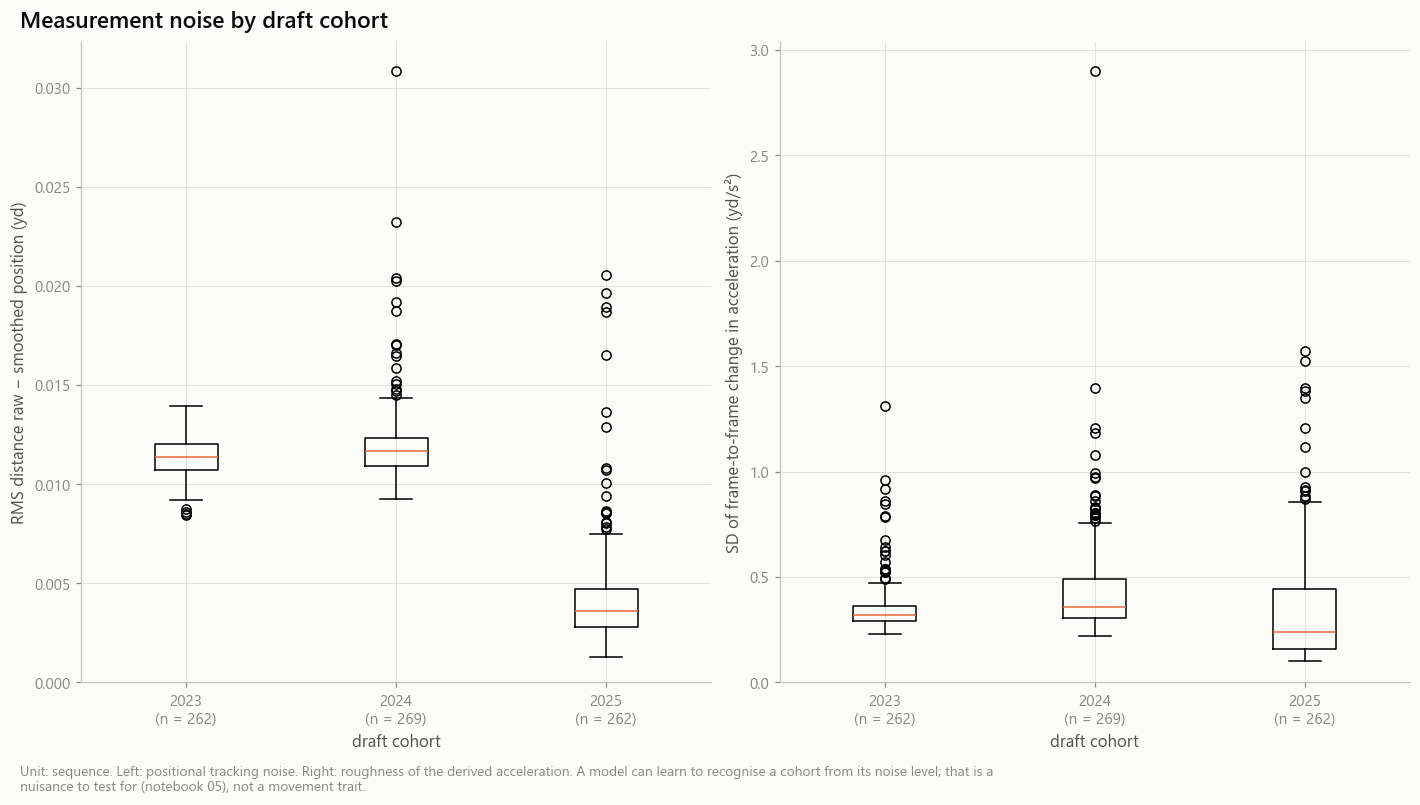

scenario,sequences,athletes,athletes_with_repeat
str,i64,i64,i64
"""S0_all""",793,418,375
"""S1_structural""",785,416,369
"""S2_signal""",734,401,333
"""S3_no_boundary""",632,378,254


draft_year,sequences,median_first_speed,share_ending_at_peak,median_pos_resid_rms,median_a_tan_roughness
i64,u32,f64,f64,f64,f64
2023,262,0.515285,0.335878,0.011361,0.317577
2024,269,0.657354,0.215613,0.011649,0.358898
2025,262,0.5245,0.293893,0.003576,0.237569


In [9]:
store.show(viz.plot_recording_window(summary), 'AM01_08_recording_window_censoring',
           {'sequences': summary.select('seq_id', 'draft_year', 'position_group', 'first_speed', 'duration_s', 'frames_after_peak')},
           source='sequence_summary', n=f'{summary.height} sequences')
store.show(viz.plot_speed_vs_displacement(ss, seed=controls.seed), 'AM01_09_speed_vs_displacement', source='sequence_frames',
           n=f'{ss.n} sequences')
store.show(viz.plot_noise(summary), 'AM01_10_measurement_noise_by_cohort',
           {'sequences': summary.select('seq_id', 'draft_year', 'pos_resid_rms', 'a_tan_roughness')},
           source='sequence_summary', n=f'{summary.height} sequences')

eligible = manifest.filter(pl.col('eligible_primary'))
scenario_rows = []
for s in ('S0_all', 'S1_structural', 'S2_signal', 'S3_no_boundary'):
    kept = eligible.filter(pl.col(s).fill_null(False))
    per_athlete = kept.group_by('nfl_id').len()
    scenario_rows.append({'scenario': s, 'sequences': kept.height, 'athletes': per_athlete.height,
                          'athletes_with_repeat': per_athlete.filter(pl.col('len') >= 2).height})
display(pl.DataFrame(scenario_rows))
display(summary.group_by('draft_year').agg(pl.len().alias('sequences'), pl.col('first_speed').median().alias('median_first_speed'),
                                           (pl.col('frames_after_peak') == 0).mean().alias('share_ending_at_peak'),
                                           pl.col('pos_resid_rms').median().alias('median_pos_resid_rms'),
                                           pl.col('a_tan_roughness').median().alias('median_a_tan_roughness')).sort('draft_year'))

## 8 · Alignment experiments

| Method | Axis | What it keeps | What it removes or distorts |
|---|---|---|---|
| A · elapsed time | seconds since the first **recorded** frame | the clock | two attempts of an athlete are shifted when the recordings start at different moments |
| B · normalised time | fraction of the recorded duration | shape | the duration — most of what the stopwatch measures; a late start still shifts it |
| C · distance | yards of path since the first recorded frame | where on the track | the origin is again the first recorded frame |
| D · speed phase | speed level reached, rising phase only | acceleration as a function of the athlete's state, independent of the recording start | how long it took to reach each speed (unless `t_rel`, re-zeroed at the reference speed, is kept); undefined after the peak |

No alignment is physically neutral. D in particular removes speed-development timing, which may be exactly what distinguishes athletes; it is compared, not assumed.

**Mechanics.** Each method is a linear interpolation inside one sequence between real frames. Grid points outside the recorded range are missing, never extrapolated or padded with a value. The original clock at every grid point is kept (`AlignedCurves.t_orig`).

**Criterion** (no NFL value). For channel $c$ and grid point $g$, a one-way random-effects decomposition over athletes with repeated attempts gives $\sigma^2_{B}(g)$ between athletes and $\sigma^2_{W}(g)$ within athlete. The integrated ICC of the curve is

$$\mathrm{ICC}_{\text{int}} = \frac{\sum_g \sigma^2_{B}(g)}{\sum_g \left[\sigma^2_{B}(g) + \sigma^2_{W}(g)\right]}$$

over grid points with enough repeated athletes. `position_adjusted` compares athletes inside their position group. The comparison is computed on the **design** athletes (the decision subset), on the other athletes (**confirm**) and on **all** (a transductive view, shown for completeness).

A high value is necessary, not sufficient: a curve can be repeatable because the alignment erased the differences between athletes. Coverage (how much of the grid the recordings fill) is reported beside it.

In [10]:
s0 = splits.filter(pl.col('repeat') == 0)
athlete_sets = {'design': s0.filter(pl.col('design_role') == 'design')['nfl_id'].to_list(),
                'confirm': s0.filter(pl.col('design_role') == 'confirm')['nfl_id'].to_list(),
                'all': s0['nfl_id'].to_list()}
amd.assert_disjoint(athlete_sets['design'], athlete_sets['confirm'], 'design vs confirm athletes')

comparison = store.build('ALIGNMENT', [al.COMPARISON],
                         lambda: {al.COMPARISON.name: al.compare_alignments(aligned, positions, athlete_sets, acfg)},
                         params={'config': acfg.params(), 'channels': EDA_CHANNELS},
                         files=[store.parquet(seq.SEQ_FRAMES), store.parquet(amd.SPLITS)])[al.COMPARISON.name]

display(Markdown('**Design athletes, position-adjusted (the view decisions are taken on)**'))
display(comparison.filter((pl.col('athlete_set') == 'design') & (pl.col('scope') == 'position_adjusted')).select(
    'method', 'channel', 'n_sequences', 'n_athletes_repeat', 'grid_points_estimable', 'coverage', 'icc_integrated',
    'icc_pointwise_median').sort('channel', 'icc_integrated', descending=[False, True], nulls_last=True))
display(Markdown('**Design against confirm: does the ordering of methods hold on athletes the decision did not see?**'))
display(comparison.filter(pl.col('scope') == 'position_adjusted').pivot(on='athlete_set', index=['channel', 'method'],
                                                                        values='icc_integrated').sort('channel', 'method'))
display(Markdown('**Pooled over positions (inflated by position differences; for reference only)**'))
display(comparison.filter((pl.col('athlete_set') == 'all') & (pl.col('scope') == 'pooled')).pivot(
    on='method', index='channel', values='icc_integrated').sort('channel'))

13:41:23 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ALIGNMENT] computing (never run)
13:41:25 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ALIGNMENT] alignment_comparison: 102 rows → warehouse/gold/advanced_movement/alignment_comparison.parquet


**Design athletes, position-adjusted (the view decisions are taken on)**

method,channel,n_sequences,n_athletes_repeat,grid_points_estimable,coverage,icc_integrated,icc_pointwise_median
str,str,i64,i64,i64,f64,f64,f64
"""speed_phase""","""a_tan""",235,110,41,0.876893,0.363576,0.422313
"""normalized_time""","""a_tan""",235,110,64,0.999335,0.21668,0.254156
"""distance""","""a_tan""",235,110,81,0.996743,0.213831,0.336935
"""elapsed_time""","""a_tan""",235,110,56,0.86076,0.196644,0.12567
"""speed_phase""","""dist""",235,110,41,0.876893,0.856855,NaN
"""elapsed_time""","""dist""",235,110,56,0.861458,0.345773,NaN
"""normalized_time""","""dist""",235,110,64,1.0,0.077817,NaN
"""speed_phase""","""lat_dev""",235,110,41,0.876893,0.440982,0.459761
"""distance""","""lat_dev""",235,110,81,0.997006,0.439213,NaN


**Design against confirm: does the ordering of methods hold on athletes the decision did not see?**

channel,method,design,confirm,all
str,str,f64,f64,f64
"""a_tan""","""distance""",0.213831,0.354673,0.312854
"""a_tan""","""elapsed_time""",0.196644,0.326281,0.28386
"""a_tan""","""normalized_time""",0.21668,0.35325,0.309365
"""a_tan""","""speed_phase""",0.363576,0.416387,0.400573
"""dist""","""elapsed_time""",0.345773,0.537163,0.479092
"""dist""","""normalized_time""",0.077817,0.386944,0.263512
"""dist""","""speed_phase""",0.856855,0.839769,0.844108
"""lat_dev""","""distance""",0.439213,0.459516,0.455853
"""lat_dev""","""elapsed_time""",0.402854,0.470085,0.446658


**Pooled over positions (inflated by position differences; for reference only)**

channel,elapsed_time,normalized_time,distance,speed_phase
str,f64,f64,f64,f64
"""a_tan""",0.340857,0.419322,0.44501,0.612804
"""dist""",0.642976,0.396674,null,0.920521
"""lat_dev""",0.446003,0.455421,0.456142,0.488893
"""speed""",0.669549,0.734075,0.944323,null
"""t_rel""",null,0.669855,0.484278,0.874131


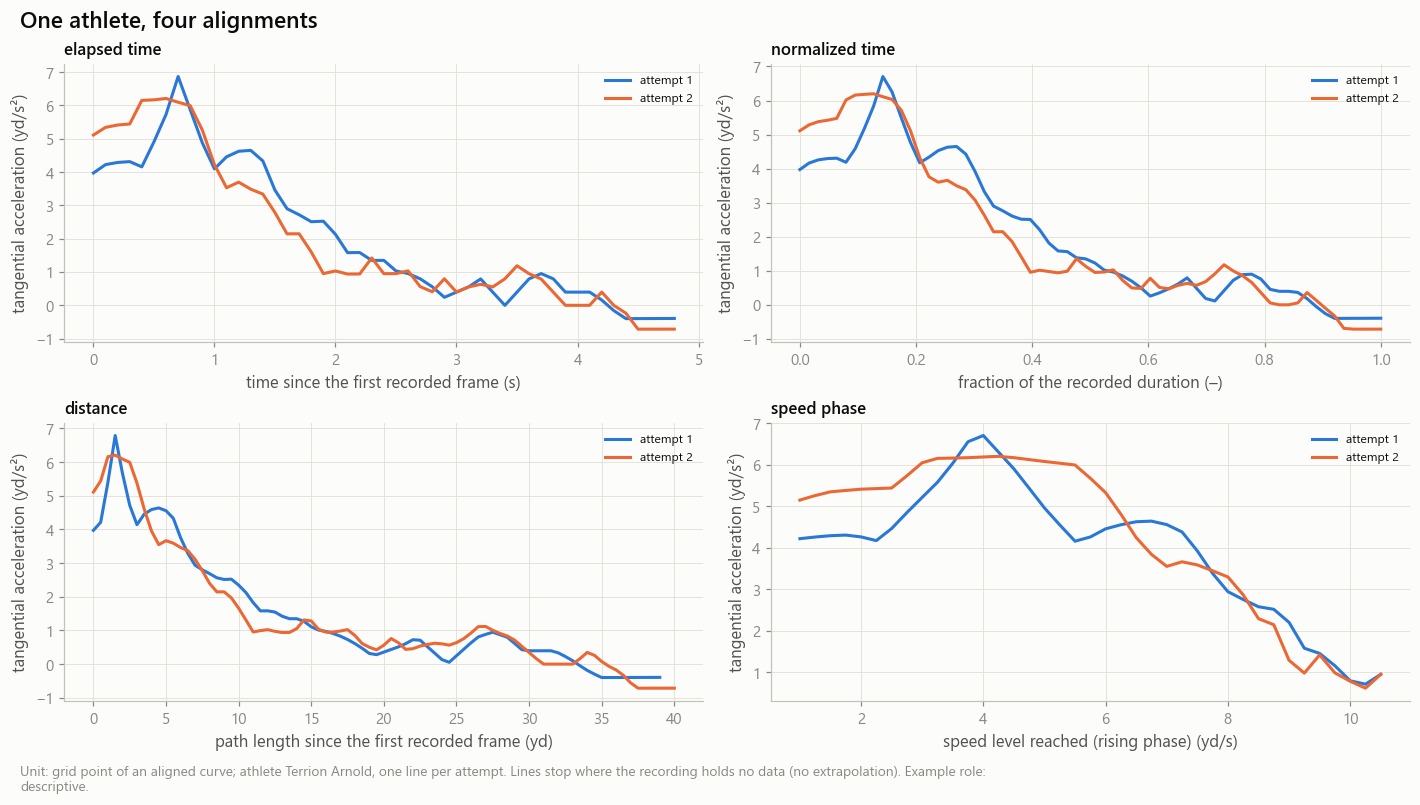

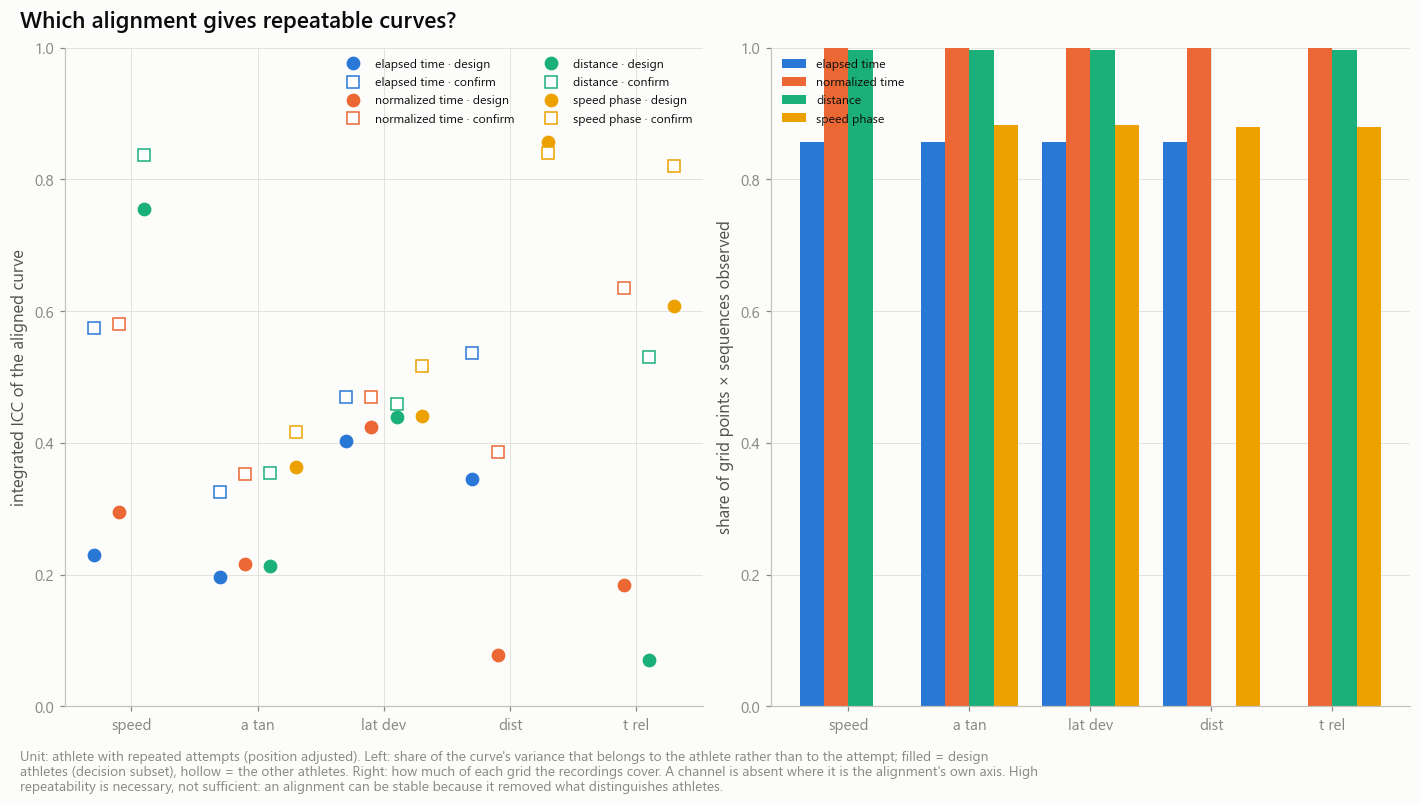

In [11]:
if repeat_examples:
    example = repeat_examples[0]
    store.show(viz.plot_alignment_example(ss, aligned, example, 'a_tan', name=names.get(example), role='descriptive'),
               'AM01_11_one_athlete_four_alignments', source='sequence_frames', n='1 athlete')
store.show(viz.plot_alignment_comparison(comparison, scope='position_adjusted'), 'AM01_12_alignment_comparison',
           {'comparison': comparison}, publication=True, source='alignment_comparison',
           n=f'{len(athlete_sets["design"])} design + {len(athlete_sets["confirm"])} confirm athletes')

## 9 · Preprocessing decisions

Record the choices **after** reading the executed outputs above. A decision left at `None` is saved as `PENDING REVIEW`, and notebook 02 will refuse to start on a pending alignment. Write the reason next to each choice; a choice made on the design athletes that does not hold on the confirm athletes should say so.

| Decision | Evidence to read |
|---|---|
| `alignment` | the three tables of section 8, figures `AM01_11`, `AM01_12` |
| `input_channels` | channel missingness (section 2), per-channel rows of the alignment comparison |
| `quality_scenario` | scenario counts (section 7); sprint rescue report §3.4 |
| `boundary_frames` | `share_boundary` in `sequence_summary`; shaded frames in section 3 |

In [12]:
CHOICES = {'alignment': None,            # 'elapsed_time' | 'normalized_time' | 'distance' | 'speed_phase'
           'input_channels': None,       # e.g. 'speed, a_tan, lat_dev'
           'quality_scenario': None,     # 'S0_all' | 'S1_structural' | 'S2_signal' | 'S3_no_boundary'
           'boundary_frames': None}      # 'keep' | 'mask in losses' | 'drop'
RATIONALE = {'alignment': '', 'input_channels': '', 'quality_scenario': '', 'boundary_frames': ''}

design_view = comparison.filter((pl.col('athlete_set') == 'design') & (pl.col('scope') == 'position_adjusted')
                                & pl.col('icc_integrated').is_not_null())
best = design_view.sort('icc_integrated', descending=True).group_by('channel', maintain_order=True).first()
evidence = {'alignment': 'highest integrated ICC per channel on design athletes: ' + '; '.join(
                f'{r["channel"]} → {r["method"]} ({r["icc_integrated"]:.3f}, coverage {r["coverage"]:.2f})' for r in best.iter_rows(named=True)),
            'input_channels': 'channel missingness (section 2) and alignment_comparison.csv',
            'quality_scenario': 'scenario counts (section 7): ' + '; '.join(
                f'{r["scenario"]} keeps {r["athletes_with_repeat"]} athletes with a repeat' for r in scenario_rows),
            'boundary_frames': f'median share of boundary frames per sequence: {summary["share_boundary"].median():.3f}'}
decisions = eda.decisions_table(evidence, CHOICES, RATIONALE)
if controls.save_tables:
    decisions = store.write(decisions, eda.DECISIONS, 'DECISIONS', {'run_mode': controls.run_mode, 'seed': controls.seed})
display(decisions)

outputs = [seq.SEQ_FRAMES, eda.SUMMARY, al.COMPARISON, eda.DECISIONS]
display(pl.DataFrame([{'output': c.name, 'kind': c.kind, 'grain': c.area, 'key': ', '.join(c.key),
                       'saved': store.exists(c), 'path': cfg.paths.rel(store.parquet(c))} for c in outputs]))

13:41:29 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:DECISIONS] preprocessing_decisions: 4 rows → warehouse/gold/advanced_movement/preprocessing_decisions.parquet


decision,options,evidence,choice,status,rationale
str,str,str,str,str,str
"""alignment""","""elapsed_time | normalized_time | distance | speed_phase""","""highest integrated ICC per channel on design athletes: dist → speed_phase (0.857, coverage 0.88); speed → dist…","""""","""PENDING REVIEW""",""""""
"""input_channels""","""subset of the channel registry""","""channel missingness (section 2) and alignment_comparison.csv""","""""","""PENDING REVIEW""",""""""
"""quality_scenario""","""S0_all | S1_structural | S2_signal | S3_no_boundary""","""scenario counts (section 7): S0_all keeps 375 athletes with a repeat; S1_structural keeps 369 athletes with a …","""""","""PENDING REVIEW""",""""""
"""boundary_frames""","""keep | mask in losses | drop""","""median share of boundary frames per sequence: 0.118""","""""","""PENDING REVIEW""",""""""


output,kind,grain,key,saved,path
str,str,str,str,bool,str
"""sequence_frames""","""dataset""","""sequence × frame""","""seq_id, frame""",true,"""warehouse/gold/advanced_movement/sequence_frames.parquet"""
"""sequence_summary""","""table""","""sequence""","""seq_id""",true,"""warehouse/gold/advanced_movement/sequence_summary.parquet"""
"""alignment_comparison""","""table""","""method × channel × athlete set × scope""","""method, channel, athlete_set, scope""",true,"""warehouse/gold/advanced_movement/alignment_comparison.parquet"""
"""preprocessing_decisions""","""table""","""decision""","""decision""",true,"""warehouse/gold/advanced_movement/preprocessing_decisions.parquet"""


## Interpretation
_To be written after execution. Placeholders — do not fill from expectation._

- **Channels:** _which carry athlete information, which are mostly noise or undefined, which change sign with the run direction._
- **Repeat attempts:** _what differs between an athlete's attempts on the recording clock, and what survives in the phase plane._
- **Same stopwatch:** _whether athletes with the same official forty show visibly different runs — on one attempt each._
- **Position and cohort:** _how much of the curve shape is position, how much is cohort noise._
- **Censoring:** _how often the recording starts late or ends at the peak, and for whom._
- **Alignment:** _which method is most repeatable per channel on the design athletes, whether the ordering holds on the confirm athletes, and what each method costs in coverage and in removed information._

## Limitations
- Two attempts per athlete: within-athlete variance rests on one difference per athlete, and it is unstable inside small position groups.
- The alignment criterion rewards repeatability only. It cannot tell a stable trait from a stable artefact, and it says nothing about NFL relevance.
- Pointwise variance components are summed without modelling the correlation along the grid; the integrated ICC is a descriptive index without an interval here (bootstrap intervals come with the representations in notebook 05).
- The design subset is about 30 % of the athletes, so its estimates are noisy; that is the price of keeping preprocessing choices away from most athletes.
- Signs of the lateral channels are not comparable across cohorts until the handedness of the coordinate frame is verified.
- Examples are single attempts chosen by rule. They illustrate; they are not evidence of a repeatable difference.

## Decision for the next notebook
_After review:_ record `CHOICES` and `RATIONALE` in section 9 and rerun that cell. Notebook 02 (functional PCA baseline) reads `sequence_frames`, `split_registry` and `preprocessing_decisions`; it fits every component inside training folds only.